# Atividade 2 — Regressão linear múltipla em PyTorch

> **Peso:** esta atividade vale o **dobro** das outras.

## Objetivo
Treinar uma regressão linear com **várias variáveis de entrada**, em PyTorch, para prever o **preço de casas na Califórnia**.
O ponto de partida é o notebook `2.6_regressao_linear_salarios.ipynb`. O 2.6 tem 1 variável de entrada, aqui são 8, então o modelo passa a ser `nn.Linear(8, 1)`.

## Dataset
O California Housing vem no scikit-learn e baixa sem login.

```python
from sklearn.datasets import fetch_california_housing
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares
```

## Configuração do experimento

| Item | Especificação |
|---|---|
| Divisão dos dados | treino / validação / teste, por exemplo **70 / 15 / 15**, com `random_state` fixo |
| Padronização | `StandardScaler` nas **entradas e na saída**, ajustado **só no treino** |
| Modelo | `nn.Linear(8, 1)` |
| Função de custo | `nn.MSELoss` |
| Otimizador | `optim.SGD` |
| Baseline | prever sempre o **preço médio do treino** |

## O que o notebook deve conter

| # | Entregável | O que mostrar |
|---|---|---|
| 1 | Análise dos dados | significado de cada variável, `describe()` e gráfico de dispersão de **pelo menos 2 variáveis** contra o preço |
| 2 | Divisão treino / validação / teste | tamanhos de cada conjunto |
| 3 | Padronização | `StandardScaler` ajustado só no treino |
| 4 | Treinamento | curvas de custo de **treino** e de **validação** |
| 5 | Avaliação | **RMSE no teste, em dólares**, comparado com o baseline |
| 6 | Pesos aprendidos | os 8 pesos, quais **mais aumentam** e quais **mais diminuem** o preço previsto |
| 7 | Interpretação dos pesos | por que só faz sentido comparar os pesos entre si **porque as entradas foram padronizadas** |
| 8 | Conclusão curta | o modelo é bom o suficiente? O que tentaria para melhorar? |



In [1]:
%pip install certifi torch scikit-learn matplotlib pandas numpy

In [2]:
import io
import pathlib
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

In [3]:
import certifi
import ssl

# Usa a cadeia de certificados do pacote certifi no macOS/ambientes Python.
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

from sklearn.datasets import fetch_california_housing
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target  # 20.640 bairros; 8 variáveis; y em centenas de milhares de dólares

## Análise exploratória

As oito variáveis de entrada estão descritas na tabela. O alvo `MedHouseVal` é o valor mediano das casas no bloco, expresso em centenas de milhares de dólares (exemplo, 2,0 corresponde a aproximadamente US$ 200.000).



O que cada variável significa, describe()


## Dicionário de dados

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana das casas (anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | população do quarteirão |
| `AveOccup` | média de moradores por domicílio |
| `Latitude` | latitude do quarteirão |
| `Longitude` | longitude do quarteirão |
| **`MedHouseVal`** (alvo `y`) | valor mediano das casas (em centenas de milhares de dólares) |

In [4]:
print(type(X), X.shape)
print(type(y), y.shape)
X.head()
# y.head()

<class 'pandas.core.frame.DataFrame'> (20640, 8)
<class 'pandas.core.series.Series'> (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [5]:
dados_resumo = pd.concat([X, y.rename("MedHouseVal")], axis=1)


In [6]:
display(dados_resumo.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


None

In [7]:
display(dados_resumo.describe())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Um gráfico de dispersão de pelo menos duas variáveis contra o preço.

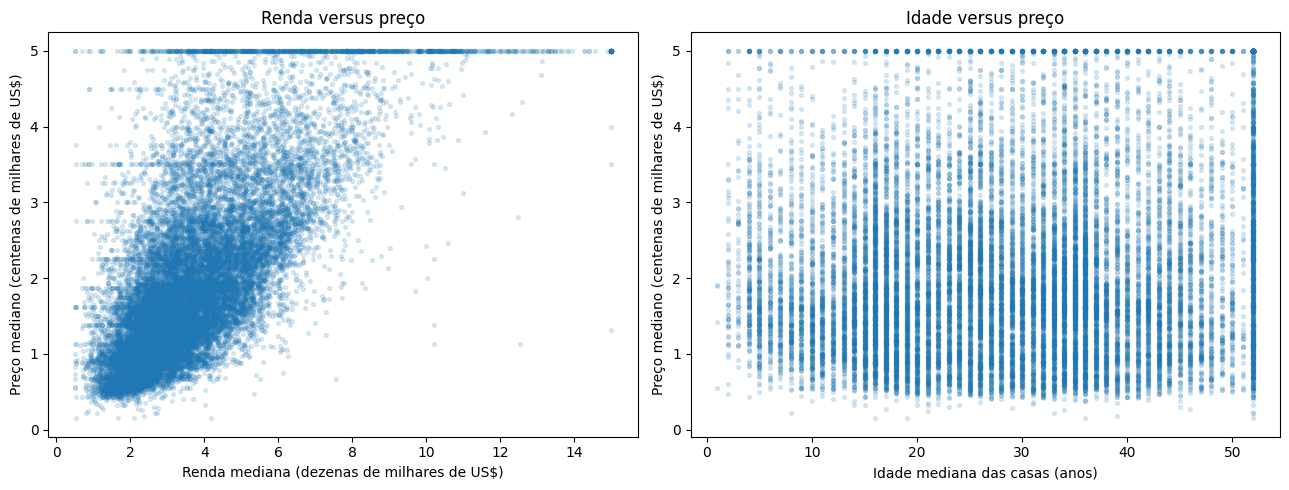

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X["MedInc"], y, alpha=0.15, s=8)
axes[0].set(xlabel="Renda mediana (dezenas de milhares de US$)", ylabel="Preço mediano (centenas de milhares de US$)", title="Renda versus preço")

axes[1].scatter(X["HouseAge"], y, alpha=0.15, s=8)
axes[1].set(xlabel="Idade mediana das casas (anos)", ylabel="Preço mediano (centenas de milhares de US$)", title="Idade versus preço")

fig.tight_layout()
plt.show()

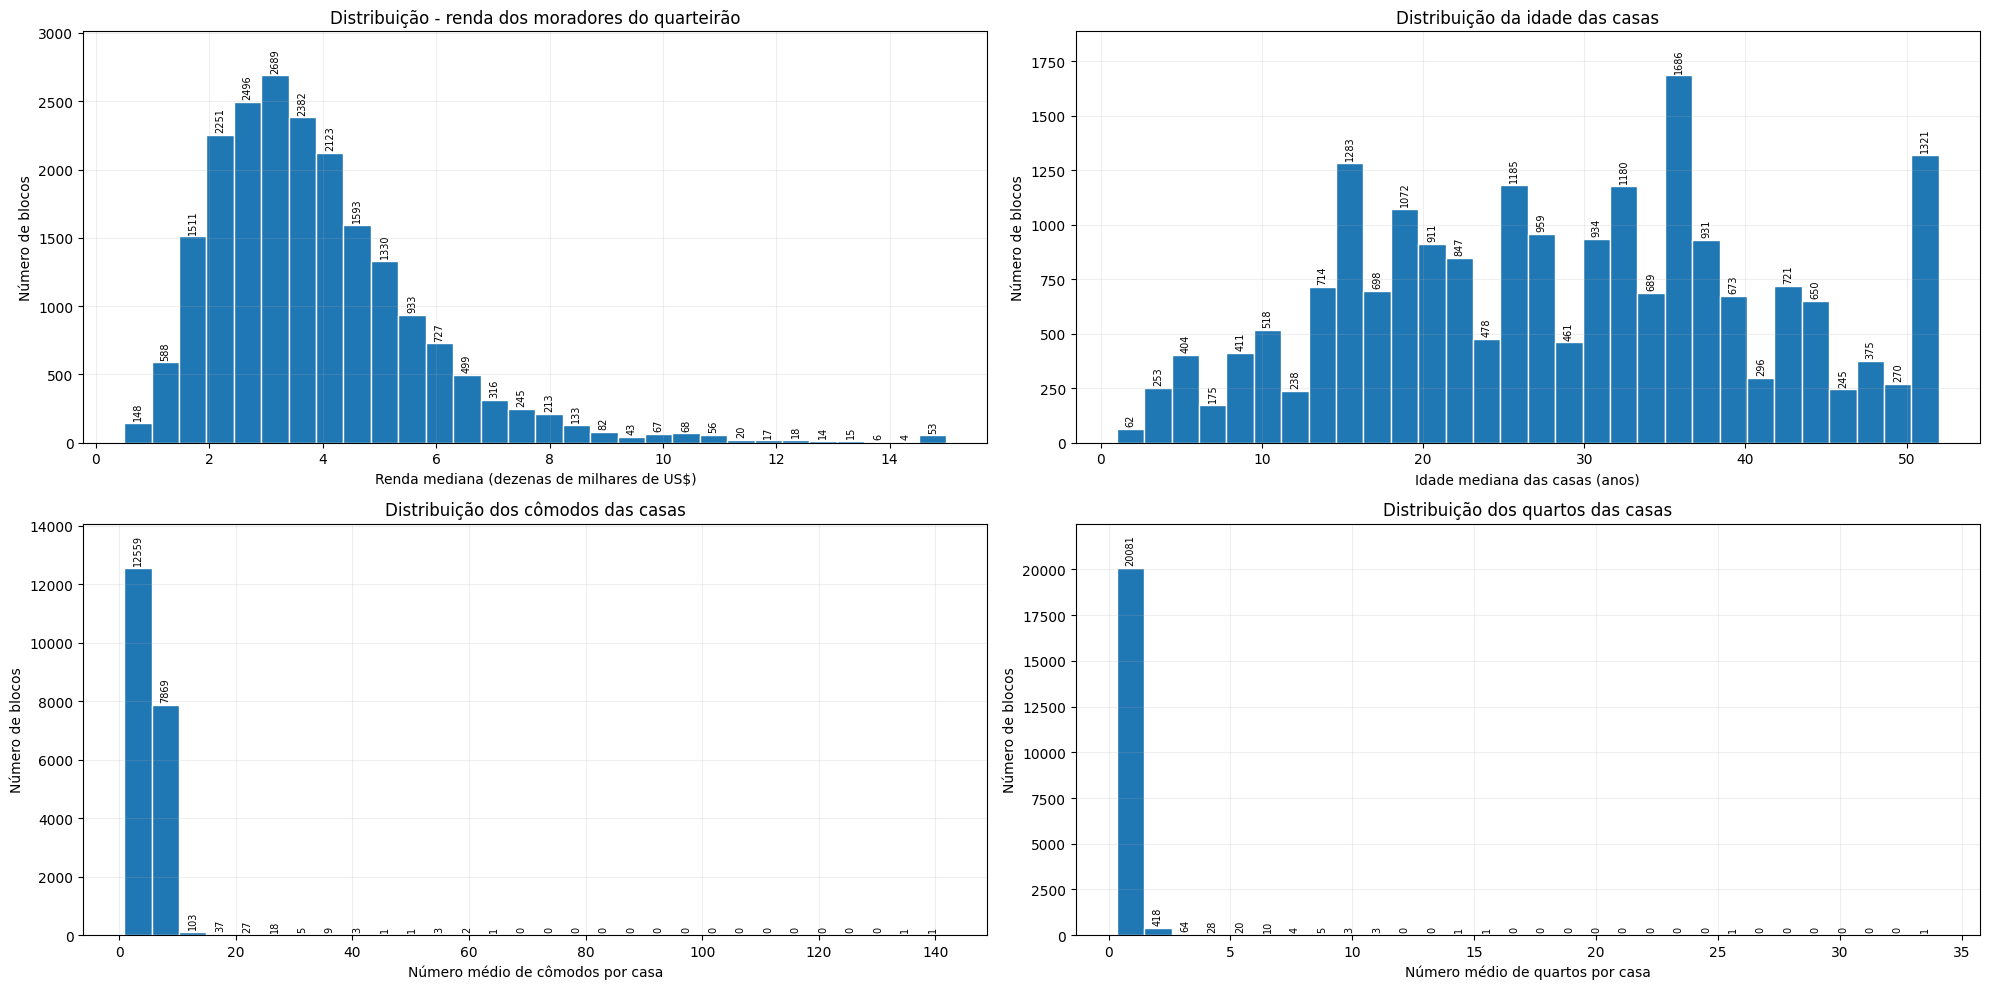

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(20, 10))

config = [
    ("MedInc",    "Renda mediana (dezenas de milhares de US$)", "Distribuição - renda dos moradores do quarteirão"),
    ("HouseAge",  "Idade mediana das casas (anos)",             "Distribuição da idade das casas"),
    ("AveRooms",  "Número médio de cômodos por casa",           "Distribuição dos cômodos das casas"),
    ("AveBedrms", "Número médio de quartos por casa",           "Distribuição dos quartos das casas"),
]

for ax, (col, xlabel, titulo) in zip(axes.flat, config):
    contagens, bordas, barras = ax.hist(X[col], bins=30, edgecolor="white")
    ax.bar_label(barras, fmt="%d", fontsize=7, rotation=90, padding=2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Número de blocos")
    ax.set_title(titulo)
    ax.grid(alpha=0.2)
    ax.margins(y=0.12)   # folga no topo para os rótulos não cortarem

fig.tight_layout()
plt.show()

Divisão em treino, validação e teste (por exemplo 70/15/15, com random_state fixo).
são 8 variável de entrada, então o modelo passa a ser nn.Linear(8, 1).

In [10]:
# 70% treino, 15% validação e 15% teste

# separa 70% treino e 30% temporário
x_train_raw, x_temp, y_train_raw, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# divide os 30% restantes ao meio (15% validação, 15% teste)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=42
)

print(f"Treino:     {x_train_raw.shape[0]} amostras")
print(f"Validação:  {x_val_raw.shape[0]} amostras")
print(f"Teste:      {x_test_raw.shape[0]} amostras")

# # 8 variáveis de entrada, 1 saída prevista
# modelo = nn.Linear(8, 1)

Treino:     14448 amostras
Validação:  3096 amostras
Teste:      3096 amostras


Padronização das entradas e da saída com StandardScaler ajustado só no treino.


In [11]:
# Ajusta os scalers somente com os dados de treino para evitar vazamento de dados.

x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw.to_numpy().reshape(-1, 1))

# Aplica aos três conjuntos os parâmetros calculados no treino.
x_train = torch.tensor(x_scaler.transform(x_train_raw), dtype=torch.float32)
x_val = torch.tensor(x_scaler.transform(x_val_raw), dtype=torch.float32)
x_test = torch.tensor(x_scaler.transform(x_test_raw), dtype=torch.float32)

y_train = torch.tensor(
    y_scaler.transform(y_train_raw.to_numpy().reshape(-1, 1)), dtype=torch.float32
)
y_val = torch.tensor(
    y_scaler.transform(y_val_raw.to_numpy().reshape(-1, 1)), dtype=torch.float32
)
y_test = torch.tensor(
    y_scaler.transform(y_test_raw.to_numpy().reshape(-1, 1)), dtype=torch.float32
)

print('Treino:    ', x_train.shape, y_train.shape)
print('Validação: ', x_val.shape, y_val.shape)
print('Teste:     ', x_test.shape, y_test.shape)

Treino:     torch.Size([14448, 8]) torch.Size([14448, 1])
Validação:  torch.Size([3096, 8]) torch.Size([3096, 1])
Teste:      torch.Size([3096, 8]) torch.Size([3096, 1])


Treinamento com nn.Linear(8, 1), nn.MSELoss e optim.SGD, com as curvas de custo de treino e de validação.


In [12]:
model = nn.Linear(8, 1)
print('weight (w1):', model.weight)
print('bias (w0):  ', model.bias)

weight (w1): Parameter containing:
tensor([[-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225]],
       requires_grad=True)
bias (w0):   Parameter containing:
tensor([0.1229], requires_grad=True)


In [13]:
model(torch.ones(5, 8))

tensor([[-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536]], grad_fn=<AddmmBackward0>)

In [14]:
model(x_train[:3])

tensor([[0.3319],
        [0.9249],
        [0.4498]], grad_fn=<AddmmBackward0>)

In [15]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight e bias

In [16]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

Epoch[20/120], Train Loss: 0.402168, Val Loss: 0.413673
Epoch[40/120], Train Loss: 0.392304, Val Loss: 0.405145
Epoch[60/120], Train Loss: 0.390904, Val Loss: 0.403969
Epoch[80/120], Train Loss: 0.390696, Val Loss: 0.403794
Epoch[100/120], Train Loss: 0.390662, Val Loss: 0.403759
Epoch[120/120], Train Loss: 0.390656, Val Loss: 0.403746


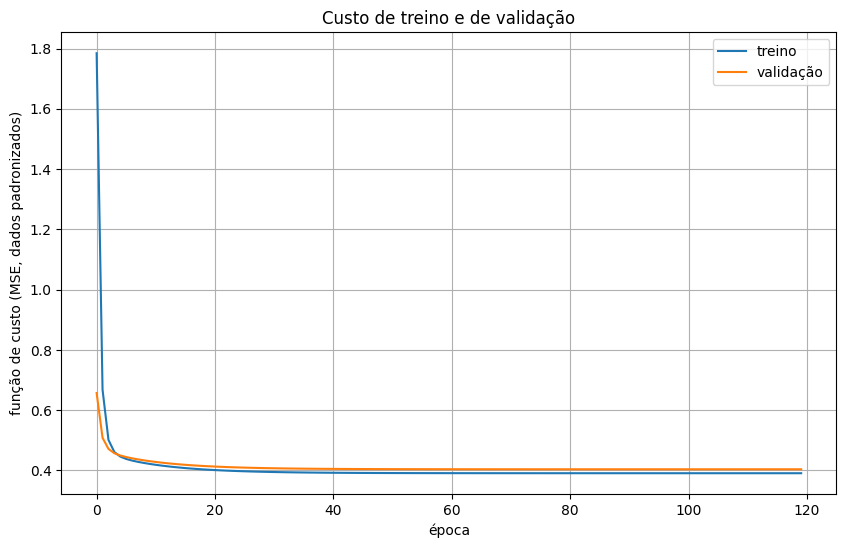

In [17]:
n_epochs = 120
w0_list = []   # bias
w1_list = []   # peso
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    w0_list.append(model.bias.item())
    w1_list.append(model.weight.detach().cpu().numpy().ravel().copy())

    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')



# Curvas de custo de treino e de validação

plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

RMSE no teste em dólares, comparado com um baseline que sempre prevê o preço médio do treino.


In [18]:
# Padroniza o teste com os scalers ajustados no treino
x_test = torch.tensor(x_scaler.transform(x_test_raw), dtype=torch.float32)

# previsão na escala padronizada e volta para a escala original
model.eval()
with torch.no_grad():
    y_test_pred_scaled = model(x_test).numpy()

y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled).ravel()
y_test_true = np.asarray(y_test_raw).ravel()

# RMSE do modelo (em US$)
rmse_modelo = np.sqrt(np.mean((y_test_pred - y_test_true) ** 2)) * 100_000

# baseline: sempre prevê a média do treino
media_treino = np.asarray(y_train_raw).mean()
rmse_baseline = np.sqrt(np.mean((media_treino - y_test_true) ** 2)) * 100_000

print(f"RMSE modelo:    US$ {rmse_modelo:,.0f}")
print(f"RMSE baseline:  US$ {rmse_baseline:,.0f}")
print(f"Melhora:        {1 - rmse_modelo / rmse_baseline:.1%}")

RMSE modelo:    US$ 72,130
RMSE baseline:  US$ 114,992
Melhora:        37.3%


Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto? Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?

Latitude     -0.768298
Longitude    -0.746573
AveRooms     -0.259956
AveOccup     -0.036092
Population   -0.000617
HouseAge      0.105941
AveBedrms     0.301728
MedInc        0.734575
dtype: float32
bias: 3.792219871456837e-09


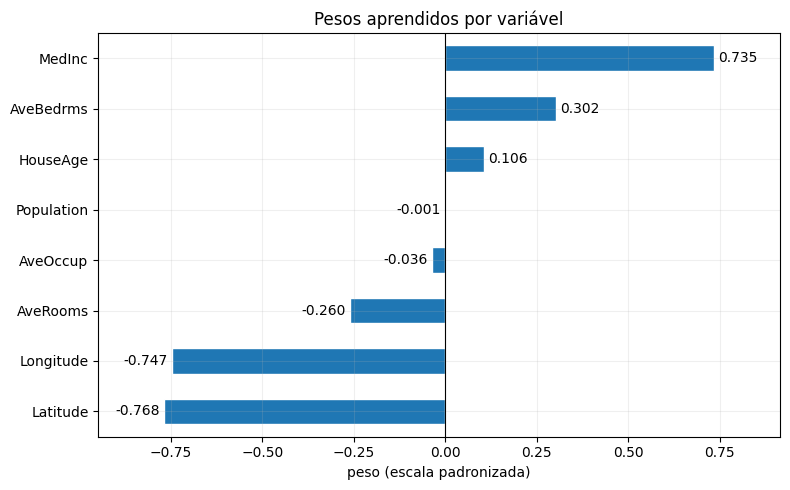

In [19]:
weights = pd.Series(
    model.weight.detach().numpy().ravel(),
    index=X.columns
).sort_values()

print(weights)
print("bias:", model.bias.item())

# gráfico com rótulos de dados
ax = weights.plot(kind="barh", figsize=(8, 5), edgecolor="white")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("peso (escala padronizada)")
ax.set_title("Pesos aprendidos por variável")
ax.grid(alpha=0.2)
ax.margins(x=0.12)   # folga nas pontas para os rótulos não cortarem
plt.tight_layout()
plt.show()

**Variáveis que mais aumentam o preço previsto:** `MedInc` (+0,734), `AveBedrms` (+0,301) e `HouseAge` (+0,105). A renda mediana é o fator de maior influência positiva.

**Variáveis que mais diminuem o preço previsto:** `Latitude` (−0,768), `Longitude` (−0,746) e `AveRooms` (−0,259). `AveOccup` e `Population` têm peso próximo de zero e quase não influenciam a previsão.


Add: AveRooms (−0,26) e AveBedrms (+0,30) têm sinais opostos por terem uma forte  correlação.

**Por que a padronização é necessária para comparar os pesos:** sem ela, cada peso depende da unidade da sua variável (`Population` em número de habitantes, `MedInc` em dezenas de milhares de dólares, `Latitude` em graus...), os valores não são comparáveis. Com a padronização, todas as entradas têm média 0 e desvio-padrão 1, e cada peso representa o efeito de 1 desvio-padrão da variável sobre o preço (em desvios-padrão de `y`), mantendo as demais variáveis constantes. Assim, o módulo do peso mede a influência relativa de cada variável.

Uma conclusão curta: o modelo é bom o suficiente? O que você tentaria para melhorar?

O modelo ficou melhor que o baseline: o RMSE no teste foi de ≈ US\$ 72.130, contra US\$ 114.992, uma redução de 37,3%. Mesmo assim, o erro continua grande para estimar preços, o que não o torna bom o suficiente para a tarefa. Para melhorar, acredito que seria possível testar modelos não lineares, como uma rede neural com camadas ocultas ou árvores de decisão, e ajustaria os hiperparâmetros usando a validação.